# 4. Application de K-Means

L'objectif est de segmenter les clients en groupes homogènes
selon leurs comportements d'achat, à partir des variables
Recency, Frequency et Monetary transformées et standardisées.

Nous utilisons K-Means avec l'initialisation k-means++.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from pathlib import Path
from sklearn.cluster import KMeans

# Charger les données standardisées
dossier_processed = Path("../data/processed")

if not dossier_processed.exists():
    dossier_processed = Path("data/processed")

rfm_scaled = pd.read_parquet(
    dossier_processed / "customer_rfm_scaled.parquet"
)

# Sélectionner uniquement les variables utilisées par K-Means
colonnes_rfm = ["Recency", "Frequency", "Monetary"]
X = rfm_scaled[colonnes_rfm]

# Vérification
print("Nombre de clients :", X.shape[0])
print("Nombre de variables :", X.shape[1])
print("Valeurs manquantes :", X.isnull().sum().sum())
print("Dimensions de X :", X.shape)

Nombre de clients : 5877
Nombre de variables : 3
Valeurs manquantes : 0
Dimensions de X : (5877, 3)


## 4.2. Recherche du nombre optimal de clusters

Nous testons différentes valeurs de K, allant de 2 à 8.

Pour chaque modèle, nous calculons l'inertie (Within-Cluster
Sum of Squares), qui mesure la somme des distances au carré
entre les observations et leurs centroïdes respectifs.

In [2]:
# Tester K de 2 à 8
valeurs_k = range(2, 9)

inerties = []

for k in valeurs_k:
    modele = KMeans(
        n_clusters=k,
        init="k-means++",
        n_init=10,
        random_state=42
    )

    modele.fit(X)

    inerties.append(modele.inertia_)

    print(f"K = {k} | Inertie = {modele.inertia_:.2f}")

K = 2 | Inertie = 8589.77
K = 3 | Inertie = 6355.68
K = 4 | Inertie = 4922.43
K = 5 | Inertie = 4102.66
K = 6 | Inertie = 3558.96
K = 7 | Inertie = 3192.28
K = 8 | Inertie = 2898.16


## 4.3. Détermination du nombre optimal de clusters

La méthode du coude consiste à représenter l'inertie en fonction
du nombre de clusters K.

Le nombre optimal de clusters correspond au point où la diminution
de l'inertie commence à ralentir significativement.

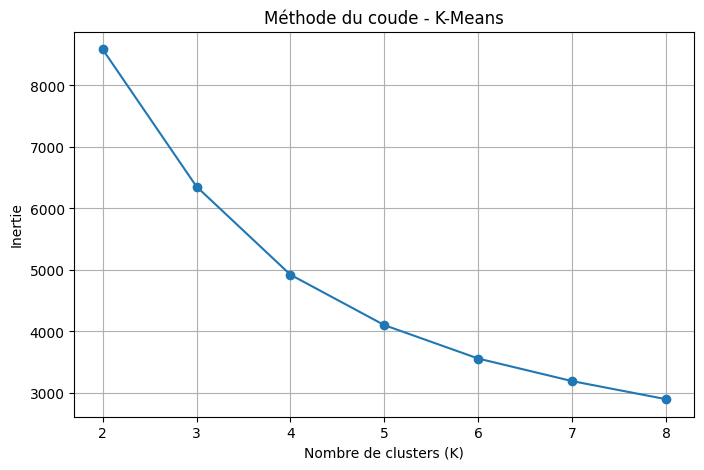

In [3]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(valeurs_k),
    inerties,
    marker="o"
)

plt.title("Méthode du coude - K-Means")
plt.xlabel("Nombre de clusters (K)")
plt.ylabel("Inertie")
plt.xticks(list(valeurs_k))
plt.grid(True)

plt.show()

De K = 2 à K = 4, l'inertie diminue fortement : les nouveaux clusters améliorent nettement la segmentation.
Après K = 4, la diminution devient progressivement moins importante.
Passer de 4 à 8 clusters apporte encore une amélioration, mais avec un gain supplémentaire de plus en plus limité.

Nous ne pouvons pas affirmer que 4 est définitivement optimal avec le seul graphique du coude. Nous allons vérifier la stabilité du résultat et examiner les profils des groupes.

## 4.4. Entraînement du modèle K-Means avec K = 4

À partir de la méthode du coude, nous retenons provisoirement
4 clusters. Nous entraînons le modèle avec l'initialisation
k-means++ et une graine aléatoire fixée pour assurer
la reproductibilité des résultats.

In [4]:
# Entraîner le modèle K-Means avec 4 clusters
modele_k4 = KMeans(
    n_clusters=4,
    init="k-means++",
    n_init=10,
    random_state=42
)

# Entraînement et prédiction des clusters
labels = modele_k4.fit_predict(X)

# Ajouter les clusters à la table RFM standardisée
rfm_scaled["Cluster"] = labels

# Afficher le nombre de clients dans chaque cluster
tailles_clusters = (
    rfm_scaled["Cluster"]
    .value_counts()
    .sort_index()
)

print("Répartition des clients par cluster :")
display(tailles_clusters.to_frame(name="Nombre de clients"))

print("Inertie du modèle :", round(modele_k4.inertia_, 2))

Répartition des clients par cluster :


,Nombre de clients
Cluster,
0,1182
1,1981
2,1247
3,1467


Inertie du modèle : 4922.43


Le cluster 1 est le plus important avec 33,71 % des clients.
Le cluster 0 est le plus petit avec 20,11 %.
Les quatre groupes ont des tailles raisonnables : aucun ne semble contenir seulement quelques clients isolés.

## 4.5. Analyse de la sensibilité aux initialisations

K-Means dépend de l'initialisation des centroïdes.
Afin d'évaluer la stabilité de la segmentation, nous entraînons
plusieurs modèles avec différentes graines aléatoires.

Nous comparons les partitions obtenues à l'aide de l'Adjusted
Rand Index (ARI), en prenant le modèle de référence (seed = 42)
comme point de comparaison.

In [6]:
from sklearn.metrics import adjusted_rand_score

# Différentes graines aléatoires
seeds = [0, 21, 42, 7, 100]

resultats_stabilite = []
labels_reference = rfm_scaled["Cluster"].values

for seed in seeds:

    modele = KMeans(
        n_clusters=4,
        init="k-means++",
        n_init=10,
        random_state=seed
    )

    labels_test = modele.fit_predict(X)

    ari = adjusted_rand_score(
        labels_reference,
        labels_test
    )

    resultats_stabilite.append({
        "Seed": seed,
        "Inertie": modele.inertia_,
        "ARI": ari
    })

df_stabilite = pd.DataFrame(resultats_stabilite)

display(df_stabilite)

,Seed,Inertie,ARI
0,0,4922.454995,0.997163
1,21,4922.404650,0.998788
2,42,4922.428285,1.000000
3,7,4922.480153,0.997324
4,100,4922.480153,0.997324


L'analyse de sensibilité aux initialisations montre une excellente stabilité de K-Means pour K = 4. Les valeurs de l'ARI varient entre 0,9972 et 1, ce qui indique une très forte similarité entre les partitions obtenues avec différentes graines aléatoires. Les valeurs d'inertie sont également très proches, confirmant la robustesse de la solution retenue.

## 4.6. Profilage et interprétation des clusters

Après avoir entraîné et vérifié la stabilité du modèle,
nous analysons les caractéristiques de chaque cluster.

Les profils sont étudiés à partir des valeurs RFM originales
afin de conserver une interprétation métier compréhensible.

In [11]:
import pandas as pd
from pathlib import Path

# Chemin des données
dossier_processed = Path("../data/processed")

if not dossier_processed.exists():
    dossier_processed = Path("data/processed")

# Charger la table RFM originale
rfm = pd.read_parquet(
    dossier_processed / "customer_rfm.parquet"
)

# Vérification
print("Dimensions :", rfm.shape)
display(rfm.head())

Dimensions : (5877, 4)


,Customer ID,Recency,Frequency,Monetary
0,12346.0,326,12,77556.46
1,12347.0,2,8,4921.53
2,12348.0,75,5,1658.40
3,12349.0,19,3,3678.69
4,12350.0,310,1,294.40


In [12]:
# Associer les clusters aux données RFM originales
rfm_result = rfm.copy()
rfm_result["Cluster"] = labels_reference

# Calculer les effectifs et les moyennes par cluster
profil_clusters = rfm_result.groupby("Cluster").agg(
    Nombre_clients=("Customer ID", "count"),
    Recency_moyenne=("Recency", "mean"),
    Frequency_moyenne=("Frequency", "mean"),
    Monetary_moyen=("Monetary", "mean")
).round(2)

# Ajouter le pourcentage de clients
profil_clusters["Pourcentage_clients"] = (
    profil_clusters["Nombre_clients"] / len(rfm_result) * 100
).round(2)

display(profil_clusters)

,Nombre_clients,Recency_moyenne,Frequency_moyenne,Monetary_moyen,Pourcentage_clients
Cluster,,,,,
0,1182,27.42,19.35,10736.25,20.11
1,1981,394.49,1.38,316.83,33.71
2,1247,28.23,3.04,844.14,21.22
3,1467,227.53,5.09,1962.93,24.96


Cluster 0 — Clients VIP et très fidèles
20,11 %

1 182 clients
- Récence moyenne : 27 jours.
- Fréquence moyenne : 19,35 commandes.
- Dépense moyenne : 10 736,25 £.
Clients récents, très actifs et à forte valeur commerciale. Ils constituent un segment prioritaire pour la fidélisation.

Cluster 1 — Clients inactifs et occasionnels
33,71 %

1 981 clients
- Récence moyenne : 394 jours.
- Fréquence moyenne : 1,38 commande.
- Dépense moyenne : 316,83 £.
Ce sont des clients qui ont généralement peu commandé et qui n'ont pas acheté depuis longtemps. Ils représentent une cible pour les campagnes de réactivation.

Cluster 2 — Clients récents à potentiel
21,22 %

1 247 clients
- Récence moyenne : 28 jours.
- Fréquence moyenne : 3,04 commandes.
- Dépense moyenne : 844,14 £.
Clients relativement récents, avec une fréquence et une dépense modérées. Ils peuvent évoluer vers le segment VIP grâce à des actions de fidélisation.

Cluster 3 — Clients intermédiaires à risque
24,96 %

1 467 clients
- Récence moyenne : 228 jours.
- Fréquence moyenne : 5,09 commandes.
- Dépense moyenne : 1 962,93 £.
Ces clients ont un historique d'achat plus important que le cluster 1, mais leur activité récente est faible. Une campagne de réengagement pourrait limiter leur perte.

In [13]:
# Profil détaillé des clusters : moyennes et médianes
profil_detaille = rfm_result.groupby("Cluster").agg(
    Nombre_clients=("Customer ID", "count"),

    Recency_moyenne=("Recency", "mean"),
    Recency_mediane=("Recency", "median"),

    Frequency_moyenne=("Frequency", "mean"),
    Frequency_mediane=("Frequency", "median"),

    Monetary_moyen=("Monetary", "mean"),
    Monetary_mediane=("Monetary", "median")
).round(2)

display(profil_detaille)

,Nombre_clients,Recency_moyenne,Recency_mediane,Frequency_moyenne,Frequency_mediane,Monetary_moyen,Monetary_mediane
Cluster,,,,,,,
0,1182,27.42,16.0,19.35,13.0,10736.25,4920.44
1,1981,394.49,402.0,1.38,1.0,316.83,273.34
2,1247,28.23,24.0,3.04,3.0,844.14,720.90
3,1467,227.53,184.0,5.09,5.0,1962.93,1457.19


In [14]:
import joblib

# Sauvegarder les clients avec leurs clusters
rfm_result.to_parquet(
    dossier_processed / "customer_rfm_clusters.parquet",
    index=False
)

# Sauvegarder le modèle K-Means entraîné
joblib.dump(
    modele_k4,
    dossier_processed / "kmeans_model_k4.joblib"
)

# Sauvegarder les profils des clusters
profil_detaille.to_csv(
    dossier_processed / "cluster_profiles.csv"
)

print("Livrables K-Means sauvegardés avec succès.")

Livrables K-Means sauvegardés avec succès.
